# Regression from images — look at your data first

Most failed projects fail here, not in the model. Before training anything, answer:
1. **What range and spread does the target have?** (and how well would guessing the average already do?)
2. **Are there outliers or impossible values?** (a typo in `labels.csv` can dominate the loss)
3. **Is the target visible in the image at all?** (if a human couldn't estimate it, the model won't either)

In [1]:
# Run this cell first.
# On Colab it clones the kit and installs what's missing; locally it just finds the repo root.
import os, sys, subprocess
from pathlib import Path

if "google.colab" in sys.modules and not Path("cvkit").exists():
    subprocess.run(["git", "clone", "-q", "https://github.com/standungan/computer-vision-starter-kit"], check=True)
    os.chdir("computer-vision-starter-kit")
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "pyyaml", "scikit-learn", "gradio"], check=True)
while not Path("cvkit").exists() and Path.cwd() != Path.cwd().parent:
    os.chdir(Path.cwd().parent)          # notebooks live 3 folders below the repo root
sys.path.insert(0, os.getcwd())
print("working in", Path.cwd().name)

working in computer-vision-starter-kit


In [2]:
%config InlineBackend.figure_format = "jpeg"
%config InlineBackend.print_figure_kwargs = {"bbox_inches": "tight", "pil_kwargs": {"quality": 90}}   # keeps saved notebooks small

from PIL import Image

from cvkit.config import load_config
from cvkit.synthetic import make_demo_data
from cvkit.utils import seed_everything

# quick.yaml = small synthetic demo, runs on a laptop CPU in minutes.
# Swap in default.yaml (bigger, pretrained) or your own config + data when you're ready.
CONFIG = "tasks/regression/configs/quick.yaml"
cfg = load_config(CONFIG)
seed_everything(cfg["seed"])

if not Path(cfg["data"]["root"]).exists():          # first run: create the demo dataset
    make_demo_data("regression", cfg)
print("task:", "regression", "| data:", cfg["data"]["root"], "| outputs:", cfg["output"]["dir"])

task: regression | data: data/demo/regression | outputs: outputs/regression_quick


## How the data is organised
An `images/` folder plus `labels.csv` with exactly one numeric column after the file name. Training standardises the target (subtract the *train* mean, divide by the *train* std) so the network learns values near 0 instead of, say, 0–400; predictions are converted back to your units.

## The target distribution

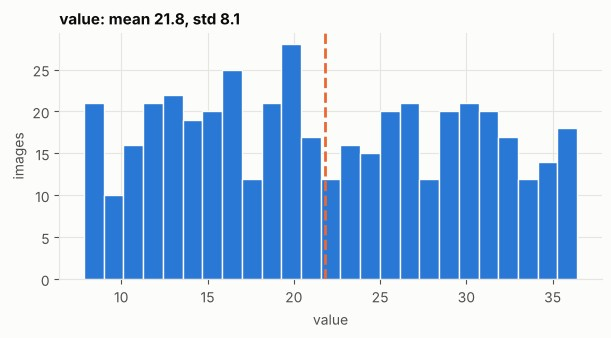

range 7.8 .. 36.4
baseline: always predicting the mean would be off by 7.01 on average (MAE)


In [3]:
import numpy as np
import matplotlib.pyplot as plt
from cvkit.viz import BLUE, ORANGE
from tasks.regression.data import build_datasets

ds = build_datasets(cfg)
samples = ds["samples"]
values = np.array([v for _, v in samples])
name = ds["stats"]["target_name"]

fig, ax = plt.subplots(figsize=(7, 3.2))
ax.hist(values, bins=25, color=BLUE, edgecolor="#fcfcfb")
ax.axvline(values.mean(), color=ORANGE, linestyle="--")
ax.set_xlabel(name); ax.set_ylabel("images"); ax.set_title(f"{name}: mean {values.mean():.1f}, std {values.std():.1f}")
plt.show()
print(f"range {values.min():.1f} .. {values.max():.1f}")
print(f"baseline: always predicting the mean would be off by {np.abs(values - values.mean()).mean():.2f} on average (MAE)")

## Low, middle and high values side by side
Can *you* see the difference? If not, the model will struggle too.

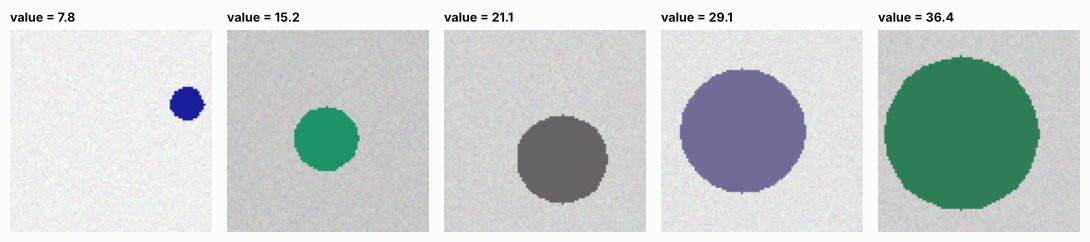

In [4]:
from PIL import Image
from cvkit.viz import image_grid

order = np.argsort(values)
idx = [order[int(q * (len(order) - 1))] for q in (0.0, 0.25, 0.5, 0.75, 1.0)]
_ = image_grid([Image.open(samples[i][0]) for i in idx], [f"{name} = {values[i]:.1f}" for i in idx], cols=5, cell=2.2)

## Augmentation
For regression, augmentation **must not change the target.** Flips and small rotations keep a circle's radius; zooming or cropping would not, so the config has no zoom. Ask of every augmentation: *does the answer stay the same?*

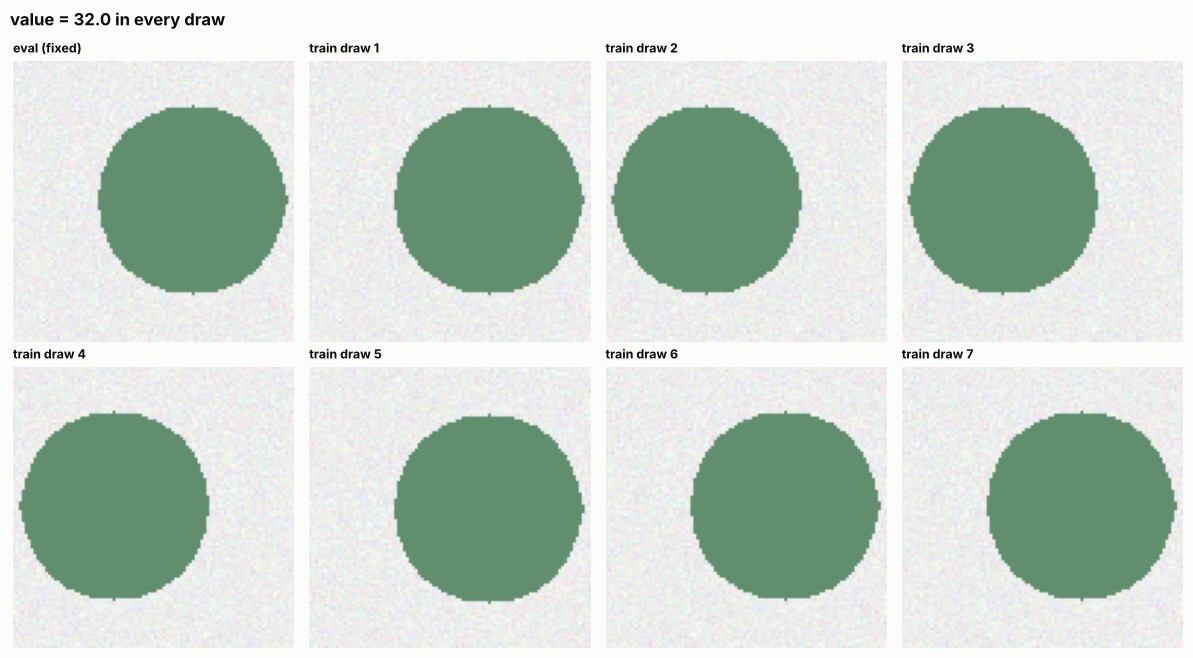

In [5]:
from cvkit.data import denormalize, image_transforms
from cvkit.viz import image_grid

size, aug = cfg["data"]["image_size"], cfg["data"]["augment"]
train_tf, eval_tf = image_transforms(size, aug, True), image_transforms(size, aug, False)
path, value = samples[0]
img = Image.open(path).convert("RGB")
shown = [denormalize(eval_tf(img))] + [denormalize(train_tf(img)) for _ in range(7)]
_ = image_grid(shown, ["eval (fixed)"] + [f"train draw {i}" for i in range(1, 8)], cols=4, suptitle=f"{name} = {value:.1f} in every draw")

## What the model will actually receive
One batch from the training loader, exactly as `train()` gets it:

images: (16, 3, 96, 96) | targets: (16,) torch.float32
train stats used to standardise: {'mean': 21.691, 'std': 7.969, 'target_name': 'value'}


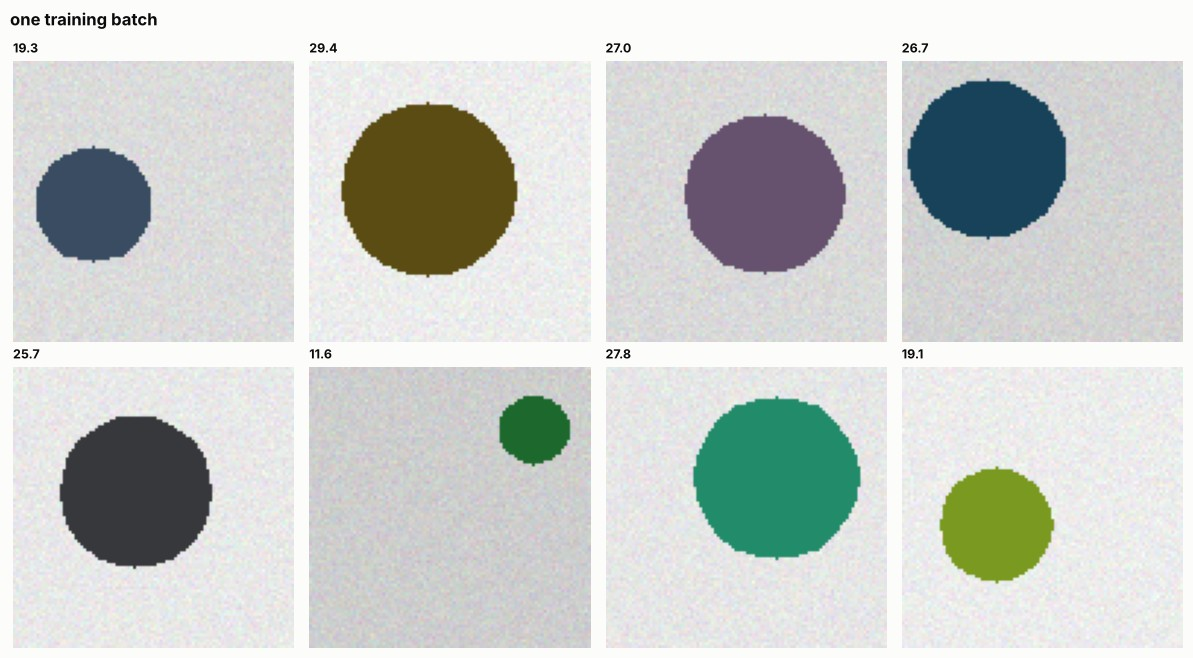

In [6]:
from cvkit.data import denormalize
from cvkit.viz import image_grid
from tasks.regression.data import build_loaders

loaders = build_loaders(cfg)
images, targets = next(iter(loaders["train"]))
print("images:", tuple(images.shape), "| targets:", tuple(targets.shape), targets.dtype)
print("train stats used to standardise:", {k: (round(v, 3) if isinstance(v, float) else v) for k, v in loaders["stats"].items()})
_ = image_grid([denormalize(i) for i in images[:8]], [f"{float(t):.1f}" for t in targets[:8]], cols=4, suptitle="one training batch")

## Before moving on
- [ ] The target's range and units make sense
- [ ] You checked a few of the largest and smallest values by eye
- [ ] No augmentation changes the target
- [ ] You know the baseline MAE the model must beat

Next: **[02_train_and_evaluate](02_train_and_evaluate.ipynb)**.